# Best Pittsburgh Neighborhood — Environment (Traffic)
Lower measured car traffic may mean less congestion and vehicle noise. We compare **median cars per day** at counted locations, not actual decibel levels. The dataset is historical (2017–2021).

## 1. Traffic data by neighborhood

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML

file = Path('Traffic_Count_Data.csv')
if not file.exists():
    file = Path('Best Neighborhood - Environment') / file
traffic = pd.read_csv(file)

# Keep every source record; use only records with a neighborhood and a valid car count for the ranking.
clean = traffic.assign(
    neighborhood=traffic['neighborhood'].astype('string').str.strip().replace('', pd.NA),
    cars_per_day=pd.to_numeric(traffic['average_daily_car_traffic'], errors='coerce')
)
valid = clean.dropna(subset=['neighborhood', 'cars_per_day'])
valid = valid[valid['cars_per_day'] >= 0]

sites = valid.groupby('neighborhood')['cars_per_day'].agg(['count', 'median', 'mean'])
names = sorted(clean['neighborhood'].dropna().unique())
summary = sites.reindex(names).rename(columns={
    'count': 'Sites', 'median': 'Median cars/day', 'mean': 'Mean cars/day'
})
summary.index.name = 'Neighborhood'
summary['Sites'] = summary['Sites'].fillna(0).astype(int)
summary[['Median cars/day', 'Mean cars/day']] = summary[['Median cars/day', 'Mean cars/day']].round(1)

print(f'{len(traffic)} source records | {len(valid)} usable traffic counts | {len(summary)} neighborhoods')
display(HTML(f'<details><summary>View all {len(traffic)} original CSV records (all {traffic.shape[1]} columns)</summary>'
             f'<div style="max-height:350px;overflow:auto">{traffic.to_html(index=False, na_rep="(missing)")}</div></details>'))
display(HTML('<div style="max-height:360px;overflow:auto">' +
             summary.sort_values('Median cars/day', na_position='last').to_html() + '</div>'))


420 source records | 285 usable traffic counts | 74 neighborhoods


_id,id,device_id,record_oid,count_start_date,count_end_date,average_daily_car_traffic,average_daily_bike_traffic,counter_number,counter_type,speed_limit,max_speed,median_speed,percent_over_limit,speed85_percent,speed95_percent,longitude,latitude,neighborhood,council_district,ward,tract,public_works_division,pli_division,police_zone,fire_zone
1,1011743669,85,1445865260.0,2019-04-18,2019-04-26,4949.0,(missing),6,StatTrak,25.0,(missing),29.0,77.0,34.0,37.00,-79.967772,40.455733,Polish Hill,7.0,6.0,42003060500,6.0,6.0,2.0,2-6
2,1026101993,140,1121444006.0,2019-01-24,(missing),(missing),(missing),(missing),Intersection Study,(missing),(missing),(missing),(missing),(missing),(missing),-79.952249,40.466157,Central Lawrenceville,7.0,9.0,42003090200,2.0,9.0,2.0,3-6
3,1032382575,11,1539892711.0,2018-08-28,2018-09-04,(missing),(missing),(missing),(missing),35.0,63.0,33.0,28.0,38.0,41.00,-80.076469,40.460717,Windgap,2.0,28.0,42003563000,5.0,28.0,6.0,1-16
4,103627606,9,734195080.0,2018-07-17,2018-08-01,2741.0,(missing),(missing),StatTrak,25.0,61.0,28.0,70.0,31.0,33.00,-79.914335,40.437379,Squirrel Hill South,5.0,14.0,42003140800,3.0,14.0,4.0,2-18
5,1039546167,144,(missing),(missing),(missing),(missing),(missing),(missing),(missing),(missing),(missing),(missing),(missing),(missing),(missing),-80.019211,40.490794,Perry North,1.0,26.0,42003260200,1.0,26.0,1.0,1-15
6,1041392556,76,571347213.0,2019-03-22,2019-03-29,1046.0,(missing),2,StatTrak,25.0,(missing),19.0,2.0,21.0,23.00,-80.014234,40.458106,Central Northside,6.0,25.0,42003250300,1.0,25.0,1.0,1-21
7,1047444948,17,1366891391.0,2018-10-18,(missing),(missing),(missing),(missing),(missing),25.0,(missing),(missing),(missing),(missing),(missing),-79.942273,40.446282,Squirrel Hill North,8.0,14.0,42003140100,3.0,14.0,4.0,2-26
8,1053645660,87,804208919.0,2019-04-18,2019-04-26,3015.0,(missing),4,StatTrak,25.0,(missing),26.0,58.0,31.0,34.00,-79.964592,40.457119,Polish Hill,7.0,6.0,42003060500,6.0,6.0,2.0,2-6
9,1073440033,156,1736165318.0,2017-07-28,(missing),(missing),(missing),(missing),Intersection Study,(missing),(missing),(missing),(missing),(missing),(missing),-79.960385,40.438983,Central Oakland,3.0,4.0,42003040500,3.0,4.0,4.0,2-14
10,1092885547,143,(missing),(missing),(missing),(missing),(missing),(missing),(missing),(missing),(missing),(missing),(missing),(missing),(missing),-79.920958,40.467294,East Liberty,9.0,11.0,42003111300,2.0,11.0,5.0,3-8


,Sites,Median cars/day,Mean cars/day
Neighborhood,,,
South Side Flats,1,115.0,115.0
Lincoln Place,1,126.0,126.0
Lincoln-Lemington-Belmar,1,195.0,195.0
Elliott,3,338.0,1342.7
Fineview,1,419.0,419.0
Highland Park,15,421.0,1564.7
Allegheny West,1,477.0,477.0
Manchester,10,584.0,2129.3
New Homestead,1,666.0,666.0


## 2. Best picks and Traffic Score

20 neighborhoods have at least five measured locations (lower traffic is better).


,Rank,Sites,Median cars/day,Traffic score / 100
Neighborhood,,,,
Highland Park,1,15,421.0,100.0
Manchester,2,10,584.0,72.1
Carrick,3,7,868.0,48.5
Central Northside,4,5,877.0,48.0
Bloomfield,5,14,1015.0,41.5
Marshall-Shadeland,6,7,1043.0,40.4
Central Lawrenceville,7,6,1361.0,30.9
Perry North,8,9,1410.0,29.9
Point Breeze,9,8,1468.0,28.7


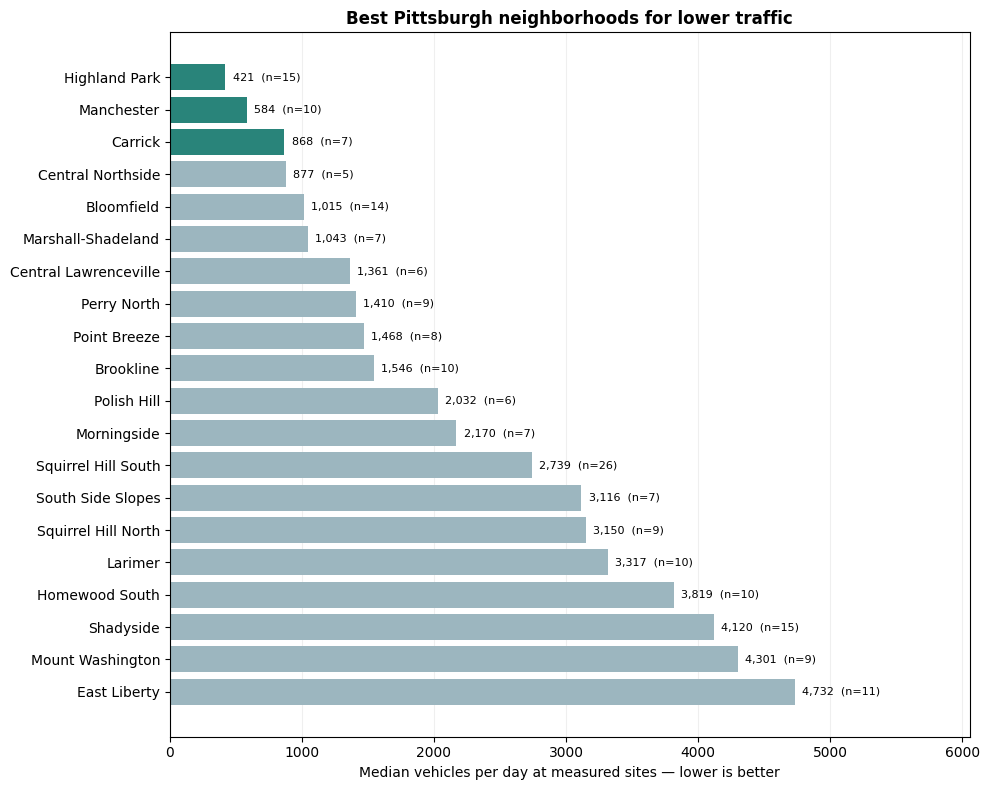

In [2]:
# Require five measured locations before treating a neighborhood as a reliable pick.
qualified = summary[summary['Sites'] >= 5].sort_values('Median cars/day').copy()
qualified['Rank'] = qualified['Median cars/day'].rank(method='min').astype(int)
qualified['Traffic score / 100'] = (100 * qualified['Median cars/day'].min()
                                     / qualified['Median cars/day']).round(1)
print(f'{len(qualified)} neighborhoods have at least five measured locations (lower traffic is better).')
display(qualified[['Rank', 'Sites', 'Median cars/day', 'Traffic score / 100']])

# The chart highlights the three lowest-traffic qualifying neighborhoods.
ordered = qualified.sort_values('Median cars/day', ascending=False)
colors = ['#29847A' if n in qualified.head(3).index else '#9CB6BF' for n in ordered.index]
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(ordered.index, ordered['Median cars/day'], color=colors)
for i, (_, row) in enumerate(ordered.iterrows()):
    ax.text(row['Median cars/day'] + 55, i,
            f"{row['Median cars/day']:,.0f}  (n={int(row['Sites'])})", va='center', fontsize=8)
ax.set_xlim(0, ordered['Median cars/day'].max() * 1.28)
ax.set_xlabel('Median vehicles per day at measured sites — lower is better')
ax.set_title('Best Pittsburgh neighborhoods for lower traffic', weight='bold')
ax.grid(axis='x', alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()
(root := file.parent / 'figures').mkdir(exist_ok=True)
plt.savefig(root / 'ranked_neighborhoods.png', dpi=170, bbox_inches='tight')
plt.show()
